# Revenue Forecaster - walkthrough
Reproduces the headline, the reach-adjusted forecast and the backtest from `data/`.

In [1]:
import sys; sys.path.insert(0, '../src')
from pingtree_forecaster import data, model, backtest
P = data.load_params(); D = data.load_partners()
cfg = model.default_cfg(P)
F = model.forecast(D['partners'], cfg, P)
print(f"full-reach ceiling: {F['rev']:,.0f} EUR  (eligible buyers: {F['eligible']})")
assert round(F['rev']) == 115371

full-reach ceiling: 115,371 EUR  (eligible buyers: 40)


In [2]:
Fr = model.forecast(D['partners'], cfg, P, reach=True)
print(f"reach-adjusted: {Fr['rev']:,.0f} EUR")

reach-adjusted: 16,300 EUR


In [3]:
import pandas as pd
b = backtest.run(D, P)
df = pd.DataFrame(b['walk_forward']); df['error_%'] = (df.model/df.actual-1)*100
print(df.round(0).to_string(index=False))
print(backtest.summarize(b['walk_forward']))

  month   actual    model    naive  error_%
2025-03 527489.0 351982.0 368911.0    -33.0
2025-04 458637.0 429698.0 454992.0     -6.0
2025-05 478520.0 505009.0 536701.0      6.0
2025-06 457528.0 406214.0 428446.0    -11.0
2025-07 502494.0 491269.0 518282.0     -2.0
2025-08 496929.0 639628.0 672000.0     29.0
2025-09 480207.0 557136.0 579344.0     16.0
2025-10 396224.0 567792.0 587275.0     43.0
2025-11 324293.0 430259.0 443210.0     33.0
2025-12 339788.0 390848.0 401399.0     15.0
2026-01 349751.0 296710.0 304507.0    -15.0
2026-02 105374.0 103839.0 106765.0     -1.0
{'mape': 0.17577430299462443, 'bias': 0.0596852168306519, 'n': 12}


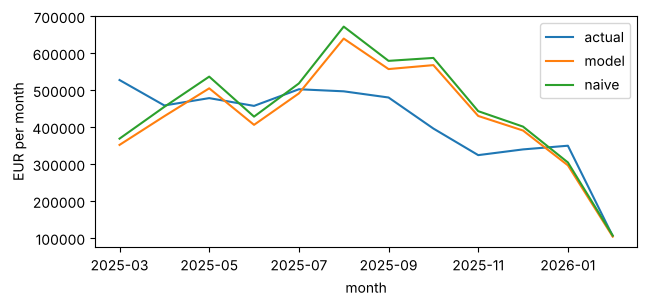

In [4]:
import matplotlib.pyplot as plt
ax = df.plot(x='month', y=['actual','model','naive'], figsize=(7,3)); ax.set_ylabel('EUR per month'); plt.show()

In [5]:
rows = F['rows']
print(pd.DataFrame([{'pos': r['pos'], 'acceptance_%': round(r['accEff']*100,2), 'EPL': round(r['eplEff'],2), 'revenue': round(r['rev'])} for r in rows]).head(10).to_string(index=False))

 pos  acceptance_%   EPL  revenue
   1          0.65 29.59    19202
   2          0.65 17.31    11171
   3          0.80 17.30    13613
   4          1.70  6.22    10366
   5          0.74  4.48     3170
   6          1.00  3.88     3721
   7          0.74  3.31     2323
   8          0.04  3.14      107
   9          2.85  2.71     7233
  10          0.13  2.70      308
